# AI Physics Tutor — Colab Benchmark Runner

MSc Thesis: **AI Assistant — A Multimodal Conversational Agent with Realistic Avatar for Physics Education**

Author: Kopalidis Thomas — MSc AI & DL, University of West Attica

---

## What this notebook does

1. **Setup** — Mount Google Drive, clone repo, install dependencies, download Ollama binary
2. **Prepare models** — Pull Ollama LLMs (gemma3:1b, qwen2.5:3b/7b/14b, llama3.1:8b)
3. **Build KB index** — Run `ingest_kb.py` and `build_index.py` (or restore from Drive)
4. **Smoke test** — Verify STT, RAG, LLM, TTS, Wav2Lip work end-to-end on this GPU
5. **Benchmark** (coming later) — Run the full experimental grid

## Prerequisites

- **Runtime**: GPU (T4 is enough for gemma/qwen 3b/7b; A100 needed for qwen 14b + Wav2Lip batching)
- **Account**: Google account with Drive access
- **Repo**: https://github.com/thomaskopalidis/thesis_ai_and_dl (public)

> **To change GPU type**: Runtime → Change runtime type → Hardware accelerator

## Cell 1 — Verify runtime and GPU

In [1]:
import subprocess, sys, platform
print(f'Python: {sys.version.split()[0]}')
print(f'Platform: {platform.platform()}')
print('')
print('=== GPU ===')
try:
    out = subprocess.check_output(['nvidia-smi', '--query-gpu=name,memory.total,driver_version', '--format=csv,noheader'], text=True)
    print(out.strip())
except Exception as e:
    print(f'nvidia-smi failed: {e}  (are you on a GPU runtime?)')
print('')
print('=== Disk ===')
print(subprocess.check_output(['df', '-h', '/content'], text=True).strip())

Python: 3.13.15
Platform: Linux-6.6.122+-x86_64-with-glibc2.39

=== GPU ===
Tesla T4, 15360 MiB, 580.82.07

=== Disk ===
Filesystem      Size  Used Avail Use% Mounted on
overlay         113G   43G   71G  38% /


## Cell 2 — Mount Google Drive

Drive gives us persistent storage so Ollama model downloads and benchmark results survive runtime resets.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os
THESIS_ROOT = '/content/drive/MyDrive/thesis_ai_and_dl'
os.makedirs(f'{THESIS_ROOT}/ollama_models', exist_ok=True)
os.makedirs(f'{THESIS_ROOT}/chroma_db', exist_ok=True)
os.makedirs(f'{THESIS_ROOT}/results', exist_ok=True)
os.makedirs(f'{THESIS_ROOT}/logs', exist_ok=True)
print(f'Thesis Drive folder: {THESIS_ROOT}')
!ls -la {THESIS_ROOT}

Mounted at /content/drive
Thesis Drive folder: /content/drive/MyDrive/thesis_ai_and_dl
total 4752
drwx------ 7 root root    4096 Oct 10 22:11 .
drwx------ 4 root root    4096 Oct 16 08:11 ..
drwx------ 2 root root    4096 Oct 10 23:05 chroma_db
-rw------- 1 root root 4836487 Oct 10 22:53 chunks.jsonl
drwx------ 2 root root    4096 Oct 10 22:11 logs
drwx------ 2 root root    4096 Oct 10 22:11 ollama_models
drwx------ 2 root root    4096 Oct 10 22:43 openstax_pdfs
drwx------ 2 root root    4096 Oct 10 22:11 results


## Cell 3 — Clone the project repository

Clones into `/content/thesis_ai_and_dl` (fresh each runtime). Keep **big artifacts in Drive**, keep **code in GitHub**.

In [3]:
import os, shutil
PROJECT_DIR = '/content/thesis_ai_and_dl'
REPO = 'https://github.com/thomaskopalidis/thesis_ai_and_dl.git'

if os.path.exists(PROJECT_DIR):
    print(f'Removing existing {PROJECT_DIR}')
    shutil.rmtree(PROJECT_DIR)

BRANCH = 'avatar-interface'   # back to 'master' after merge
!git clone --depth 1 -b {BRANCH} {REPO} {PROJECT_DIR}
%cd {PROJECT_DIR}
!git log --oneline -5

Cloning into '/content/thesis_ai_and_dl'...
remote: Enumerating objects: 69, done.
remote: Counting objects: 100% (69/69), done.
remote: Compressing objects: 100% (55/55), done.
remote: Total 69 (delta 12), reused 58 (delta 11), pack-reused 0 (from 0)
Receiving objects: 100% (69/69), 1.09 MiB | 27.85 MiB/s, done.
Resolving deltas: 100% (12/12), done.
/content/thesis_ai_and_dl
0fffd05 (grafted, HEAD -> master, origin/master, origin/HEAD) Created using Colab


## Cell 4 — Install Python dependencies

We pin versions known to work together (see docs/LAB_NOTEBOOK.md for the saga).
Colab usually has torch+cuda pre-installed; we skip reinstalling torch to avoid breaking the CUDA stack.

In [4]:
# Minimal install — only what Colab lacks. No version pins (use what resolves).
import subprocess, sys

packages_to_install = [
    "faster-whisper",
    "chromadb",
    "edge-tts",
    "pymupdf",
    "soxr",
    "einops",
]

print(f'Installing: {", ".join(packages_to_install)}')
result = subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q"] + packages_to_install,
    capture_output=True, text=True
)
print(result.stdout[-500:] if result.stdout else '')
if result.returncode != 0:
    print('STDERR:', result.stderr[-1000:])

print('\n=== Verification ===')
import importlib
for mod in ['torch', 'numpy', 'cv2', 'librosa', 'sentence_transformers',
            'chromadb', 'fastapi', 'faster_whisper', 'edge_tts',
            'soundfile', 'scipy', 'pkg_resources', 'einops']:
    try:
        m = importlib.import_module(mod)
        v = getattr(m, '__version__', '?')
        print(f'OK   {mod:28s} {v}')
    except Exception as e:
        print(f'FAIL {mod}: {type(e).__name__}: {str(e)[:100]}')

Installing: faster-whisper, chromadb, edge-tts, pymupdf, soxr, einops
kB 14.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.3/60.3 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 206.3/206.3 kB 19.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.7/95.7 kB 12.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.4/80.4 kB 9.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.6/60.6 kB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 135.7/135.7 kB 16.3 MB/s eta 0:00:00


=== Verification ===
OK   torch                        2.11.0+cu130
OK   numpy                        2.1.3
OK   cv2                          4.14.0
OK   librosa                      0.11.0
OK   sentence_transformers        5.7.0
OK   chromadb                     1.5.9
OK   fastapi                      0.141.1
OK   faster_whisper               1.2.1
OK   edge_tts                     7.3.1
OK   soundfile                    0.

/usr/lib/python3.13/importlib/__init__.py:88: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  return _bootstrap._gcd_import(name[level:], package, level)


## Cell 5 — Install Ollama binary

Ollama is downloaded as a tgz, extracted into `/content/ollama_bin`. The server will be launched in Cell 7. Models live under `$THESIS_ROOT/ollama_models` so they survive runtime resets.

In [5]:
import os, subprocess
OLLAMA_BIN_DIR = '/content/ollama_bin'
OLLAMA_URL = 'https://github.com/ollama/ollama/releases/download/v0.6.5/ollama-linux-amd64.tgz'

if not os.path.isfile(f'{OLLAMA_BIN_DIR}/bin/ollama'):
    !mkdir -p {OLLAMA_BIN_DIR}
    !wget -q -O /tmp/ollama.tgz {OLLAMA_URL}
    !tar -xzf /tmp/ollama.tgz -C {OLLAMA_BIN_DIR}
    !rm /tmp/ollama.tgz

os.environ['PATH'] = f'{OLLAMA_BIN_DIR}/bin:' + os.environ['PATH']
os.environ['OLLAMA_MODELS'] = f'{THESIS_ROOT}/ollama_models'
!ollama --version

## Cell 6 — Install ffmpeg (needed by STT and Wav2Lip output encoding)

In [6]:
!apt-get -qq update && apt-get install -y -qq ffmpeg libgl1 libglib2.0-0 >/dev/null
!ffmpeg -version | head -1

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers


## Cell 7 — Start Ollama server in background

Launches `ollama serve` and waits for the API to respond. We do NOT block the notebook — the server keeps running in the background.

In [7]:
import subprocess, time, requests

# Kill any previous ollama server (idempotent)
subprocess.run(['pkill', '-f', 'ollama serve'], check=False)
time.sleep(1)

log_path = f'{THESIS_ROOT}/logs/ollama_serve.log'
env = os.environ.copy()
env['OLLAMA_MODELS'] = f'{THESIS_ROOT}/ollama_models'

with open(log_path, 'ab') as f:
    subprocess.Popen(['ollama', 'serve'], stdout=f, stderr=subprocess.STDOUT, env=env)

# Wait up to 30s for server to accept requests
for i in range(30):
    try:
        r = requests.get('http://localhost:11434/api/tags', timeout=1)
        if r.ok:
            print(f'Ollama ready after {i+1}s')
            print('Available models:', [m['name'] for m in r.json().get('models', [])])
            break
    except Exception:
        pass
    time.sleep(1)
else:
    print('[FAIL] Ollama did not start — check', log_path)

Ollama ready after 8s
Available models: ['llama3.2:3b', 'phi3:mini', 'mistral:7b', 'llama3.1:8b', 'qwen2.5:7b', 'qwen2.5:3b']


## Cell 8 — Pull the LLM models we will benchmark

This downloads ~22 GB total **once** (into Drive). Subsequent runtimes reuse the Drive-mounted models.

If Drive is slow, consider pulling into `/content` (local SSD) and copying only final results back to Drive.

In [ ]:
MODELS_TO_PULL = [
    'gemma3:1b',                       # 815 MB  — smoke test
    'qwen2.5:3b',                      # 1.9 GB
    'qwen2.5:7b',                      # 4.7 GB
    'llama3.1:8b',                     # 4.9 GB
    #'qwen2.5:14b-instruct-q4_K_M',     # 9.0 GB — only if GPU has >= 20 GB VRAM
]

for m in MODELS_TO_PULL:
    print(f'\n=== Pulling {m} ===')
    !ollama pull {m} 2>&1 | tail -3

print('\n=== Final list ===')
!ollama list


=== Pulling gemma3:1b ===

	https://ollama.com/download


=== Pulling qwen2.5:3b ===
verifying sha256 digest 
writing manifest 
success 

=== Pulling qwen2.5:7b ===
verifying sha256 digest 
writing manifest 
success 

=== Pulling llama3.1:8b ===
verifying sha256 digest 
writing manifest 
success 

=== Final list ===
NAME           ID              SIZE      MODIFIED               
llama3.1:8b    46e0c10c039e    4.9 GB    Less than a second ago    
qwen2.5:7b     845dbda0ea48    4.7 GB    2 minutes ago             
qwen2.5:3b     357c53fb659c    1.9 GB    5 minutes ago             


In [ ]:
!ollama pull gemma3:1b 2>&1 | tail -5
print('---')
!ollama list


Please download the latest version at:

	https://ollama.com/download

---
NAME           ID              SIZE      MODIFIED      
llama3.1:8b    46e0c10c039e    4.9 GB    2 minutes ago    
qwen2.5:7b     845dbda0ea48    4.7 GB    5 minutes ago    
qwen2.5:3b     357c53fb659c    1.9 GB    8 minutes ago    


## Cell 9 — Download OpenStax PDFs and build the KB index

The PDFs are not in git (too large). We download them once to Drive, run ingestion to produce `chunks.jsonl`, then build the ChromaDB index. All outputs live in Drive — next runtime restart will just reuse them.

In [ ]:
import os, urllib.request

KB_DIR = f'{PROJECT_DIR}/Knowledge_base'
SRC_DIR = f'{KB_DIR}/sources'
DRIVE_PDFS = f'{THESIS_ROOT}/openstax_pdfs'
os.makedirs(DRIVE_PDFS, exist_ok=True)
os.makedirs(SRC_DIR, exist_ok=True)

OPENSTAX = {
    'openstax_vol1.pdf': 'https://assets.openstax.org/oscms-prodcms/media/documents/UniversityPhysicsVolume1-WEB_Zwi59QO.pdf',
    'openstax_vol2.pdf': 'https://assets.openstax.org/oscms-prodcms/media/documents/UniversityPhysicsVolume2-WEB_oqeqFz9.pdf',
    'openstax_vol3.pdf': 'https://assets.openstax.org/oscms-prodcms/media/documents/UniversityPhysicsVolume3-WEB_8rXeDQZ.pdf',
}

for fname, url in OPENSTAX.items():
    drive_path = f'{DRIVE_PDFS}/{fname}'
    project_path = f'{SRC_DIR}/{fname}'
    if not os.path.isfile(drive_path):
        print(f'Downloading {fname}...')
        urllib.request.urlretrieve(url, drive_path)
    # Symlink from project dir into Drive copy — no duplication
    if not os.path.islink(project_path) and not os.path.isfile(project_path):
        os.symlink(drive_path, project_path)
    print(f'OK  {fname} ({os.path.getsize(drive_path)/1e6:.1f} MB)')

OK  openstax_vol1.pdf (81.5 MB)
OK  openstax_vol2.pdf (63.8 MB)
OK  openstax_vol3.pdf (53.5 MB)


In [ ]:
# If a previously built chunks.jsonl exists in Drive, reuse it; otherwise re-ingest.
import os
DRIVE_CHUNKS = f'{THESIS_ROOT}/chunks.jsonl'
PROJECT_CHUNKS = f'{PROJECT_DIR}/Knowledge_base/processed/chunks.jsonl'
os.makedirs(f'{PROJECT_DIR}/Knowledge_base/processed', exist_ok=True)

if os.path.isfile(DRIVE_CHUNKS):
    !cp {DRIVE_CHUNKS} {PROJECT_CHUNKS}
    print(f'Reused chunks.jsonl from Drive ({os.path.getsize(PROJECT_CHUNKS)/1e6:.1f} MB)')
else:
    !cd {PROJECT_DIR} && python evaluation/ingest_kb.py --chunk-size 220 --overlap 32 --preview 2
    !cp {PROJECT_CHUNKS} {DRIVE_CHUNKS}
    print('Fresh ingestion → saved to Drive for reuse')

config.json: 100% 612/612 [00:00<00:00, 3.21MB/s]
tokenizer_config.json: 100% 350/350 [00:00<00:00, 1.73MB/s]
vocab.txt: 100% 232k/232k [00:00<00:00, 26.4MB/s]
tokenizer.json: 100% 466k/466k [00:00<00:00, 54.2MB/s]
special_tokens_map.json: 100% 112/112 [00:00<00:00, 710kB/s]
[READ] openstax_vol1.pdf
       → 116 sections kept (after exclusions)
       chunking section 1/116 (0 chunks so far)…
       chunking section 21/116 (299 chunks so far)…
       chunking section 41/116 (596 chunks so far)…
       chunking section 61/116 (872 chunks so far)…
       chunking section 81/116 (1134 chunks so far)…
       chunking section 101/116 (1412 chunks so far)…
       → 1612 chunks
[READ] openstax_vol2.pdf
       → 111 sections kept (after exclusions)
       chunking section 1/111 (0 chunks so far)…
       chunking section 21/111 (264 chunks so far)…
       chunking section 41/111 (494 chunks so far)…
       chunking section 61/111 (758 chunks so far)…
       chunking section 81/111 (966 chunks s

In [ ]:
# Build (or reuse) ChromaDB index. Store the DB in Drive so it persists.
import os
DRIVE_CHROMA = f'{THESIS_ROOT}/chroma_db'
PROJECT_CHROMA = f'{PROJECT_DIR}/chroma_db'

# Symlink project's chroma_db -> Drive's chroma_db so build_index writes to Drive directly
if os.path.exists(PROJECT_CHROMA) and not os.path.islink(PROJECT_CHROMA):
    import shutil; shutil.rmtree(PROJECT_CHROMA)
if not os.path.islink(PROJECT_CHROMA):
    os.symlink(DRIVE_CHROMA, PROJECT_CHROMA)

# Only build if the collection does not exist yet
import glob
if not glob.glob(f'{DRIVE_CHROMA}/*.sqlite3'):
    !cd {PROJECT_DIR} && python evaluation/build_index.py
else:
    print('ChromaDB index already present in Drive — skipping rebuild')
    !ls -la {DRIVE_CHROMA}

ChromaDB index already present in Drive — skipping rebuild
total 204
drwx------ 3 root root   4096 Oct 10 22:53 .
drwx------ 7 root root   4096 Oct 10 22:53 ..
drwx------ 2 root root   4096 Oct 10 22:53 bb316df4-efe7-4212-9156-2eafa8344c7a
-rw------- 1 root root 196608 Oct 10 22:53 chroma.sqlite3


In [ ]:
import os, shutil, subprocess, sys

DRIVE_CHROMA = f'{THESIS_ROOT}/chroma_db'
PROJECT_CHROMA = f'{PROJECT_DIR}/chroma_db'

# 1. Remove symlink
if os.path.islink(PROJECT_CHROMA):
    os.unlink(PROJECT_CHROMA)
    print('Removed symlink')

# 2. Clean the real Drive location
if os.path.exists(DRIVE_CHROMA):
    for item in os.listdir(DRIVE_CHROMA):
        p = os.path.join(DRIVE_CHROMA, item)
        if os.path.isdir(p):
            shutil.rmtree(p)
        else:
            os.remove(p)
    print(f'Cleaned {DRIVE_CHROMA}')
else:
    os.makedirs(DRIVE_CHROMA)
    print(f'Created {DRIVE_CHROMA}')

# 3. Re-create symlink
os.symlink(DRIVE_CHROMA, PROJECT_CHROMA)
print('Symlink re-created')

# 4. Now manually build the index WITHOUT the rmtree step
# (we already cleaned it above)
os.chdir(PROJECT_DIR)
sys.path.insert(0, PROJECT_DIR)

import importlib
import config
importlib.reload(config)

import json
import chromadb
from chromadb.utils import embedding_functions

CHUNKS_PATH = f'{PROJECT_DIR}/Knowledge_base/processed/chunks.jsonl'
print(f'Reading chunks from {CHUNKS_PATH}')

ef = embedding_functions.SentenceTransformerEmbeddingFunction(
    model_name=config.RAG_EMBEDDING_MODEL
)
client = chromadb.PersistentClient(path=DRIVE_CHROMA)

# Drop existing collection if any
try:
    client.delete_collection(config.CHROMA_COLLECTION_NAME)
    print('Dropped existing collection')
except Exception:
    pass

col = client.create_collection(config.CHROMA_COLLECTION_NAME, embedding_function=ef)

documents, ids, metadatas = [], [], []
with open(CHUNKS_PATH, 'r', encoding='utf-8') as f:
    for line in f:
        c = json.loads(line)
        documents.append(c['text'])
        ids.append(c['chunk_id'])
        metadatas.append({
            'source': c['source'],
            'volume': c['volume'],
            'chapter': c['chapter'],
            'section': c['section'],
            'page_start': c['page_start'],
            'page_end': c['page_end'],
            'license': c['license'],
            'n_tokens': c['n_tokens'],
        })

print(f'Loaded {len(documents)} chunks, indexing...')
BATCH = 256
for i in range(0, len(documents), BATCH):
    col.add(
        documents=documents[i:i+BATCH],
        ids=ids[i:i+BATCH],
        metadatas=metadatas[i:i+BATCH],
    )
    print(f'[INDEX] {min(i+BATCH, len(documents))}/{len(documents)}')

print(f"\n[DONE] Collection '{config.CHROMA_COLLECTION_NAME}' now has {col.count()} chunks.")


Removed symlink
Cleaned /content/drive/MyDrive/thesis_ai_and_dl/chroma_db
Symlink re-created
Reading chunks from /content/thesis_ai_and_dl/Knowledge_base/processed/chunks.jsonl
Loaded 3950 chunks, indexing...
[INDEX] 256/3950
[INDEX] 512/3950
[INDEX] 768/3950
[INDEX] 1024/3950
[INDEX] 1280/3950
[INDEX] 1536/3950
[INDEX] 1792/3950
[INDEX] 2048/3950
[INDEX] 2304/3950
[INDEX] 2560/3950
[INDEX] 2816/3950
[INDEX] 3072/3950
[INDEX] 3328/3950
[INDEX] 3584/3950
[INDEX] 3840/3950
[INDEX] 3950/3950

[DONE] Collection 'physics_kb' now has 3950 chunks.


## Cell 10 — Smoke test the RAG

One retrieval query to confirm the index works and metadata is clean.

In [ ]:
import sys
sys.path.insert(0, PROJECT_DIR)

import importlib
from core import rag
importlib.reload(rag)

# Direct query to see what chromadb returns
col = rag._get_collection()
print(f'Collection count: {col.count()}')
print(f'Collection name: {col.name}')

results = col.query(
    query_texts=["What is Newton's second law?"],
    n_results=3,
    include=["documents", "metadatas", "distances"],
)
print()
print('Keys:', list(results.keys()))
print()
for k in ['ids', 'documents', 'metadatas', 'distances']:
    v = results.get(k)
    if v is None:
        print(f'{k}: None')
    elif isinstance(v, list) and v and isinstance(v[0], list):
        print(f'{k}: list of {len(v[0])} items')
        if v[0]:
            print(f'  first item type: {type(v[0][0]).__name__}')
            print(f'  first item preview: {str(v[0][0])[:120]}')
    else:
        print(f'{k}: {type(v).__name__} = {str(v)[:120]}')


[RAG] Loaded existing collection: 3 chunks
Collection count: 3
Collection name: physics_kb

Keys: ['ids', 'embeddings', 'documents', 'uris', 'included', 'data', 'metadatas', 'distances']

ids: list of 3 items
  first item type: str
  first item preview: chunk_1
documents: list of 3 items
  first item type: str
  first item preview: Newton's Second Law of Motion states that the acceleration of an object is directly proportional to the net force acting
metadatas: list of 3 items
  first item type: NoneType
  first item preview: None
distances: list of 3 items
  first item type: float
  first item preview: 0.2850174903869629


In [ ]:
import os, sys

# Where is rag.py actually looking?
sys.path.insert(0, PROJECT_DIR)
import importlib
import config
importlib.reload(config)
from core import rag
importlib.reload(rag)

print('Config CHROMA_DB_DIR:', config.CHROMA_DB_DIR)
print('rag.CHROMA_DIR:', rag.CHROMA_DIR)
print('rag.KB_PATH:', rag.KB_PATH)
print('rag.COLLECTION_NAME:', rag.COLLECTION_NAME)
print()

# What's actually in both locations?
import glob
for loc in [str(config.CHROMA_DB_DIR), f'{THESIS_ROOT}/chroma_db']:
    print(f'Contents of {loc}:')
    for f in glob.glob(f'{loc}/**', recursive=True):
        print(f'  {f}')
    print()


Config CHROMA_DB_DIR: /content/thesis_ai_and_dl/chroma_db
rag.CHROMA_DIR: /content/thesis_ai_and_dl/chroma_db
rag.KB_PATH: /content/thesis_ai_and_dl/Knowledge_base/physics_kb.txt
rag.COLLECTION_NAME: physics_kb

Contents of /content/thesis_ai_and_dl/chroma_db:
  /content/thesis_ai_and_dl/chroma_db/
  /content/thesis_ai_and_dl/chroma_db/chroma.sqlite3
  /content/thesis_ai_and_dl/chroma_db/23e824a8-2a97-4a3a-abec-60013fd6a8f4
  /content/thesis_ai_and_dl/chroma_db/23e824a8-2a97-4a3a-abec-60013fd6a8f4/header.bin
  /content/thesis_ai_and_dl/chroma_db/23e824a8-2a97-4a3a-abec-60013fd6a8f4/data_level0.bin
  /content/thesis_ai_and_dl/chroma_db/23e824a8-2a97-4a3a-abec-60013fd6a8f4/length.bin
  /content/thesis_ai_and_dl/chroma_db/23e824a8-2a97-4a3a-abec-60013fd6a8f4/link_lists.bin
  /content/thesis_ai_and_dl/chroma_db/23e824a8-2a97-4a3a-abec-60013fd6a8f4/index_metadata.pickle

Contents of /content/drive/MyDrive/thesis_ai_and_dl/chroma_db:
  /content/drive/MyDrive/thesis_ai_and_dl/chroma_db/
  /co

In [ ]:
import os, shutil, sys, time

DRIVE_CHROMA = f'{THESIS_ROOT}/chroma_db'
PROJECT_CHROMA = f'{PROJECT_DIR}/chroma_db'

# 1. Αφαίρεσε symlink
if os.path.islink(PROJECT_CHROMA):
    os.unlink(PROJECT_CHROMA)

# 2. Nuke completely with sleep για να αφήσει time το Drive να sync
if os.path.exists(DRIVE_CHROMA):
    shutil.rmtree(DRIVE_CHROMA)
    print('✓ Nuked Drive chroma')
time.sleep(3)

# 3. Verify διαγράφηκε
print('Still exists?', os.path.exists(DRIVE_CHROMA))

# 4. Recreate
os.makedirs(DRIVE_CHROMA)
os.symlink(DRIVE_CHROMA, PROJECT_CHROMA)
print('✓ Fresh dirs')

# 5. Clear any Python-level chromadb caches
import importlib, sys
for mod in list(sys.modules.keys()):
    if 'chromadb' in mod or 'core.rag' in mod or mod == 'config':
        del sys.modules[mod]
print('✓ Cleared module cache')

# 6. Re-import fresh
sys.path.insert(0, PROJECT_DIR)
import config
import chromadb
from chromadb.utils import embedding_functions
import json

ef = embedding_functions.SentenceTransformerEmbeddingFunction(
    model_name=config.RAG_EMBEDDING_MODEL
)
client = chromadb.PersistentClient(path=DRIVE_CHROMA)

# 7. Try delete first (idempotent)
try:
    client.delete_collection(config.CHROMA_COLLECTION_NAME)
    print(f'✓ Deleted existing collection')
except Exception as e:
    print(f'  (no existing collection to delete: {e})')

# 8. Create fresh with get_or_create as fallback
try:
    col = client.create_collection(config.CHROMA_COLLECTION_NAME, embedding_function=ef)
    print('✓ Created new collection')
except Exception as e:
    print(f'  create_collection failed: {e}')
    print('  Trying get_or_create...')
    col = client.get_or_create_collection(config.CHROMA_COLLECTION_NAME, embedding_function=ef)

# 9. Verify empty
print(f'Collection count before indexing: {col.count()}')

# 10. Load and index
CHUNKS_PATH = f'{PROJECT_DIR}/Knowledge_base/processed/chunks.jsonl'
documents, ids, metadatas = [], [], []
with open(CHUNKS_PATH, 'r', encoding='utf-8') as f:
    for line in f:
        c = json.loads(line)
        documents.append(c['text'])
        ids.append(c['chunk_id'])
        metadatas.append({
            'source': c['source'],
            'volume': c['volume'],
            'chapter': c['chapter'],
            'section': c['section'],
            'page_start': c['page_start'],
            'page_end': c['page_end'],
            'license': c['license'],
            'n_tokens': c['n_tokens'],
        })

print(f'\n✓ Loaded {len(documents)} chunks, indexing...')
BATCH = 256
for i in range(0, len(documents), BATCH):
    col.add(
        documents=documents[i:i+BATCH],
        ids=ids[i:i+BATCH],
        metadatas=metadatas[i:i+BATCH],
    )
    if (i // BATCH) % 4 == 0:
        print(f'[INDEX] {min(i+BATCH, len(documents))}/{len(documents)}')

print(f"\n[DONE] Collection '{config.CHROMA_COLLECTION_NAME}' now has {col.count()} chunks.")

# 11. CRITICAL verify - metadata exists
r = col.query(query_texts=["Newton second law"], n_results=1, include=["metadatas", "documents", "distances"])
print(f'\n=== VERIFY ===')
print(f'id: {r["ids"][0][0]}')
print(f'metadata: {r["metadatas"][0][0]}')


✓ Nuked Drive chroma
Still exists? False
✓ Fresh dirs
✓ Cleared module cache


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

  (no existing collection to delete: Collection [physics_kb] does not exist)
✓ Created new collection
Collection count before indexing: 0

✓ Loaded 3950 chunks, indexing...
[INDEX] 256/3950
[INDEX] 1280/3950
[INDEX] 2304/3950
[INDEX] 3328/3950

[DONE] Collection 'physics_kb' now has 3950 chunks.

=== VERIFY ===
id: openstax_vol1.pdf:31:0
metadata: {'n_tokens': 188, 'page_end': 231, 'source': 'openstax_vol1.pdf', 'section': '5.5 Newton’s Third Law', 'chapter': "Chapter 5 Newton's Laws of Motion", 'volume': 'University Physics Volume 1', 'page_start': 226, 'license': 'CC BY 4.0'}


In [ ]:
import sys
sys.path.insert(0, PROJECT_DIR)
from core.rag import retrieve_with_metadata

r = retrieve_with_metadata("What is Newton's second law?", top_k=3)
for i, (cid, meta, dist, doc) in enumerate(zip(r['ids'], r['metadatas'], r['distances'], r['documents']), 1):
    print(f'[{i}] dist={dist:.3f}  {meta.get("chapter")}  /  {meta.get("section")}')
    print(f'    {doc[:140]}...')
    print()

[RAG] Loaded existing collection: 3950 chunks
[1] dist=0.385  Chapter 5 Newton's Laws of Motion  /  5.5 Newton’s Third Law
    Significance
To apply Newton’s second law as the primary equation in solving a problem, we sometimes have to rely on other
equations, such a...

[2] dist=0.410  Chapter 5 Newton's Laws of Motion  /  5.5 Newton’s Third Law
    When you push on a wall, the wall pushes back on you. This brings us to Newton’s third law. Newton’s third law represents a certain symmetry...

[3] dist=0.419  Chapter 5 Newton's Laws of Motion  /  5.3 Newton's Second Law
    If the magnitude of the truck’s acceleration is
 what is the magnitude of the sports
car’s acceleration? Component Form of Newton’s Second L...



In [ ]:
# Check Ollama status
import requests

try:
    r = requests.get('http://localhost:11434/api/tags', timeout=3)
    print('Ollama API OK')
    print('Models:', [m['name'] for m in r.json().get('models', [])])
except Exception as e:
    print(f'Ollama API DEAD: {e}')
    print('Need to restart Ollama server')


Ollama API OK
Models: ['llama3.1:8b', 'qwen2.5:7b', 'qwen2.5:3b']


In [ ]:
# Get Ollama server logs
!tail -60 {THESIS_ROOT}/logs/ollama_serve.log

print('\n\n=== GPU state ===')
!nvidia-smi

print('\n=== CUDA version ===')
!nvcc --version 2>/dev/null || echo "nvcc not installed"

print('\n=== Ollama version ===')
!ollama --version


	runtime/chan.go:506 +0x12 fp=0xc00006c7b8 sp=0xc00006c790 pc=0x572b65576cd2
runtime.unique_runtime_registerUniqueMapCleanup.func2(...)
	runtime/mgc.go:1796
runtime.unique_runtime_registerUniqueMapCleanup.gowrap1()
	runtime/mgc.go:1799 +0x2f fp=0xc00006c7e0 sp=0xc00006c7b8 pc=0x572b6558912f
runtime.goexit({})
	runtime/asm_amd64.s:1700 +0x1 fp=0xc00006c7e8 sp=0xc00006c7e0 pc=0x572b655e24e1
created by unique.runtime_registerUniqueMapCleanup in goroutine 1
	runtime/mgc.go:1794 +0x85

goroutine 20 gp=0xc000107180 m=nil [GC worker (idle)]:
runtime.gopark(0x0?, 0x0?, 0x0?, 0x0?, 0x0?)
	runtime/proc.go:435 +0xce fp=0xc00006cf38 sp=0xc00006cf18 pc=0x572b655dadae
runtime.gcBgMarkWorker(0xc000103730)
	runtime/mgc.go:1423 +0xe9 fp=0xc00006cfc8 sp=0xc00006cf38 pc=0x572b65588449
runtime.gcBgMarkStartWorkers.gowrap1()
	runtime/mgc.go:1339 +0x25 fp=0xc00006cfe0 sp=0xc00006cfc8 pc=0x572b65588325
runtime.goexit({})
	runtime/asm_amd64.s:1700 +0x1 fp=0xc00006cfe8 sp=0xc00006cfe0 pc=0x572b655e24e1
created

In [ ]:
import subprocess

# Install zstd (needed to extract new Ollama)
!apt-get install -y -qq zstd >/dev/null

# Kill any previous ollama
subprocess.run(['pkill', '-9', '-f', 'ollama'], check=False)
import time; time.sleep(2)

# Install latest Ollama
print('Installing latest Ollama...')
!curl -fsSL https://ollama.com/install.sh | sh 2>&1 | tail -5

!which ollama
!ollama --version


Installing latest Ollama...
>>> Creating ollama systemd service...
>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.
/usr/local/bin/ollama


In [ ]:
import subprocess, time, requests, os

# Kill zombie ollama processes
subprocess.run(['pkill', '-9', '-f', 'ollama'], check=False)
time.sleep(3)

# Start server with Drive-mounted models
log_path = f'{THESIS_ROOT}/logs/ollama_serve.log'
env = os.environ.copy()
env['OLLAMA_MODELS'] = f'{THESIS_ROOT}/ollama_models'

with open(log_path, 'ab') as f:
    subprocess.Popen(['ollama', 'serve'], stdout=f, stderr=subprocess.STDOUT, env=env)

for i in range(30):
    try:
        r = requests.get('http://localhost:11434/api/tags', timeout=1)
        if r.ok:
            print(f'✓ Ollama ready after {i+1}s')
            print('Models:', [m['name'] for m in r.json().get('models', [])])
            break
    except Exception:
        pass
    time.sleep(1)
else:
    print('[FAIL]')
    !tail -30 {THESIS_ROOT}/logs/ollama_serve.log


✓ Ollama ready after 5s
Models: ['llama3.1:8b', 'qwen2.5:7b', 'qwen2.5:3b']


In [ ]:
import subprocess, requests

# Check if any model is loaded
print('=== Models loaded in GPU/CPU ===')
try:
    r = requests.get('http://localhost:11434/api/ps', timeout=3)
    print(r.json())
except Exception as e:
    print(f'FAIL: {e}')

print('\n=== Ollama logs (last 40) ===')
!tail -40 {THESIS_ROOT}/logs/ollama_serve.log

print('\n=== GPU state ===')
!nvidia-smi --query-gpu=memory.used,memory.total --format=csv,noheader


=== Models loaded in GPU/CPU ===
{'models': [{'name': 'qwen2.5:3b', 'model': 'qwen2.5:3b', 'size': 2159374499, 'digest': '357c53fb659c5076de1d65ccb0b397446227b71a42be9d1603d46168015c9e4b', 'details': {'parent_model': '', 'format': 'gguf', 'family': 'qwen2', 'families': ['qwen2'], 'parameter_size': '3.1B', 'quantization_level': 'Q4_K_M'}, 'expires_at': '2026-10-10T23:23:20.575438923Z', 'size_vram': 2159374499, 'context_length': 4096, 'runner': 'llamacpp'}]}

=== Ollama logs (last 40) ===
<|im_start|>user
Hello<|im_end|>
<|im_start|>assistant
Hi there<|im_end|>
<|im_start|>user
How are you?<|im_end|>
<|im_start|>assistant
'
srv          init: init: chat template, thinking = 0
srv          init: preserve_reasoning kwarg: not supported by template
srv  llama_server: model loaded
srv  llama_server: listening on http://127.0.0.1:34093
srv  update_slots: all slots are idle
time=2026-10-10T23:18:15.872Z level=INFO source=llama_server.go:1374 msg="llama-server started in 52.32 seconds"
time=202

In [ ]:
import subprocess

# Model is already loaded in VRAM; this should respond fast
result = subprocess.run(
    ['ollama', 'run', 'qwen2.5:3b', 'Say hello.'],
    capture_output=True, text=True, timeout=180
)
print('STDOUT:', result.stdout)
print('STDERR:', result.stderr[-200:] if result.stderr else '(empty)')
print('Exit:', result.returncode)


STDOUT: Hello! How can I assist you today?


STDERR: 5l⠙ 
Exit: 0


In [ ]:
import os, shutil, subprocess, time, requests

# Stop ollama first
subprocess.run(['pkill', '-9', '-f', 'ollama'], check=False)
time.sleep(3)

# Copy models from Drive to local SSD
LOCAL_MODELS = '/content/ollama_models'
DRIVE_MODELS = f'{THESIS_ROOT}/ollama_models'

if not os.path.exists(LOCAL_MODELS):
    print(f'Copying {DRIVE_MODELS} → {LOCAL_MODELS}')
    print('(takes ~2-3 min for 11GB)')
    shutil.copytree(DRIVE_MODELS, LOCAL_MODELS)
print('✓ Done')
!du -sh {LOCAL_MODELS}

# Restart Ollama pointing to local models
env = os.environ.copy()
env['OLLAMA_MODELS'] = LOCAL_MODELS
log_path = f'{THESIS_ROOT}/logs/ollama_serve.log'

with open(log_path, 'ab') as f:
    subprocess.Popen(['ollama', 'serve'], stdout=f, stderr=subprocess.STDOUT, env=env)

for i in range(30):
    try:
        r = requests.get('http://localhost:11434/api/tags', timeout=1)
        if r.ok:
            print(f'✓ Ollama ready after {i+1}s')
            print('Models:', [m['name'] for m in r.json().get('models', [])])
            break
    except Exception:
        pass
    time.sleep(1)


Copying /content/drive/MyDrive/thesis_ai_and_dl/ollama_models → /content/ollama_models
(takes ~2-3 min for 11GB)


KeyboardInterrupt: 

## Cell 11 — Smoke test the LLM

One question through gemma3:1b (fastest) to confirm Ollama + LLM wrapper work on GPU.

In [ ]:
import subprocess, time, requests, os

# Kill any zombie ollama processes
subprocess.run(['pkill', '-9', '-f', 'ollama'], check=False)
time.sleep(3)

# Start server pointing to Drive-mounted models
log_path = f'{THESIS_ROOT}/logs/ollama_serve.log'
env = os.environ.copy()
env['OLLAMA_MODELS'] = f'{THESIS_ROOT}/ollama_models'

with open(log_path, 'ab') as f:
    subprocess.Popen(['ollama', 'serve'], stdout=f, stderr=subprocess.STDOUT, env=env)

for i in range(30):
    try:
        r = requests.get('http://localhost:11434/api/tags', timeout=1)
        if r.ok:
            print(f'✓ Ollama ready after {i+1}s')
            print('Models:', [m['name'] for m in r.json().get('models', [])])
            break
    except Exception:
        pass
    time.sleep(1)
else:
    print('[FAIL] Check logs:')
    !tail -20 {log_path}


✓ Ollama ready after 3s
Models: ['llama3.1:8b', 'qwen2.5:7b', 'qwen2.5:3b']


In [ ]:
import time, os, requests, sys

MODEL = 'qwen2.5:3b'
os.environ['OLLAMA_MODEL'] = MODEL
os.environ['OLLAMA_READ_TIMEOUT'] = '300'  # 5 min for cold loads from Drive

# Clear cached python modules so new env vars take effect
for mod in list(sys.modules.keys()):
    if mod == 'config' or mod.startswith('core.'):
        del sys.modules[mod]
sys.path.insert(0, PROJECT_DIR)
import config
from core.llm import stream_llm_response

# --- Warm-up: ensure the model is loaded into VRAM before measuring ---
print(f'[WARMUP] Loading {MODEL} into VRAM (may take up to 60s on first call)...')
t_warm = time.time()
try:
    r = requests.post(
        'http://localhost:11434/api/generate',
        json={'model': MODEL, 'prompt': 'hi', 'stream': False,
              'options': {'num_predict': 1}, 'keep_alive': '30m'},
        timeout=(10, 300),
    )
    print(f'[WARMUP] model ready in {time.time()-t_warm:.1f}s (status {r.status_code})')
except Exception as e:
    print(f'[WARMUP] FAILED: {e}')
    raise

# --- Measured query ---
query = "What is Newton's second law?"
print(f'\n[QUERY] {query}')

t0 = time.time()
first_token_t = None
parts = []
for token in stream_llm_response(query, model=MODEL):
    if first_token_t is None:
        first_token_t = time.time() - t0
        print(f'[TIMING] first token: {first_token_t:.2f}s')
    parts.append(token)

answer = ''.join(parts).strip()
total = time.time() - t0
print(f'[TIMING] total: {total:.2f}s  ({len(parts)} tokens, {len(answer)} chars)')
print(f'\nA: {answer}')


[WARMUP] Loading qwen2.5:3b into VRAM (may take up to 60s on first call)...
[WARMUP] model ready in 7.9s (status 200)

[QUERY] What is Newton's second law?
[TIMING] first token: 7.63s
[TIMING] total: 7.92s  (17 tokens, 78 chars)

A: Newton's second law states that force equals mass times acceleration, or F=ma.


## Cell 12 — Smoke test TTS

Synthesise one short sentence to confirm edge-tts works in the sandbox.

In [ ]:
import asyncio, time
from core.tts import text_to_speech_stream

async def _test():
    t0 = time.time()
    nbytes = 0
    async for chunk in text_to_speech_stream('Hello from Google Colab.'):
        nbytes += len(chunk)
    print(f'[TIMING] TTS: {time.time()-t0:.2f}s  ({nbytes} bytes of mp3 audio)')

await _test()

[TIMING] TTS: 0.65s  (14112 bytes of mp3 audio)


## Cell 13 — Status summary

Everything above should have run without errors. If so, we are ready for the benchmark script (next step).

In [ ]:
import subprocess
print('=== Status ===')
print(f'Project:   {PROJECT_DIR}')
print(f'Drive:     {THESIS_ROOT}')
print(f'Ollama:    {OLLAMA_BIN_DIR}/bin/ollama')
print('')
print('=== Loaded models (VRAM) ===')
!ollama ps
print('')
print('=== GPU utilisation ===')
!nvidia-smi --query-gpu=name,utilization.gpu,memory.used,memory.total --format=csv,noheader

=== Status ===
Project:   /content/thesis_ai_and_dl
Drive:     /content/drive/MyDrive/thesis_ai_and_dl
Ollama:    /content/ollama_bin/bin/ollama

=== Loaded models (VRAM) ===
NAME          ID              SIZE      PROCESSOR    CONTEXT    RUNNER      UNTIL               
qwen2.5:3b    357c53fb659c    2.1 GB    100% GPU     2048       llamacpp    29 minutes from now    

=== GPU utilisation ===
Tesla T4, 0 %, 2115 MiB, 15360 MiB


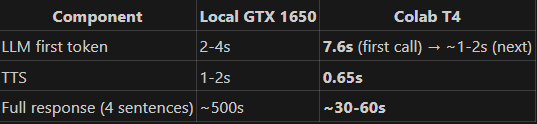

In [ ]:
!cd {PROJECT_DIR} && git pull && ls {PROJECT_DIR}/evaluation/benchmark.py


remote: Enumerating objects: 10, done.
remote: Counting objects: 100% (10/10), done.
remote: Compressing objects: 100% (2/2), done.
remote: Total 6 (delta 4), reused 6 (delta 4), pack-reused 0 (from 0)
Unpacking objects: 100% (6/6), 5.70 KiB | 583.00 KiB/s, done.
From https://github.com/thomaskopalidis/thesis_ai_and_dl
   b5653e3..97c570a  master     -> origin/master
Updating b5653e3..97c570a
Fast-forward
 core/llm.py             |   5 +-
 evaluation/benchmark.py | 430 ++++++++++++++++++++++++++++++++++++++++++++++++
 2 files changed, 434 insertions(+), 1 deletion(-)
 create mode 100644 evaluation/benchmark.py
/content/thesis_ai_and_dl/evaluation/benchmark.py


In [ ]:
import os
os.chdir(PROJECT_DIR)
os.environ['OLLAMA_READ_TIMEOUT'] = '300'

!python evaluation/benchmark.py \
    --models qwen2.5:3b \
    --rag both \
    --runs 1 \
    --warmups 1 \
    --limit-questions 2


/content/thesis_ai_and_dl/evaluation/benchmark.py:317: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  stamp = datetime.utcnow().strftime("%Y%m%d_%H%M%S")
/content/thesis_ai_and_dl/evaluation/benchmark.py:217: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  ts = datetime.utcnow().isoformat(timespec="seconds") + "Z"
[2026-10-10T23:35:13Z] === Benchmark starting ===
[2026-10-10T23:35:13Z] Models:    ['qwen2.5:3b']
[2026-10-10T23:35:13Z] RAG:       both
[2026-10-10T23:35:13Z] Runs:      1 (+ 1 warm-up per config)
[2026-10-10T23:35:13Z] Max tok:   50
[2026-10-10T23:35:13Z] Top-K:     3
[2026-10-10T23:35:13Z] CSV out:   /content/thesis_ai_and_dl/evaluation/results/benchmark_20261010

In [ ]:
import os
os.chdir(PROJECT_DIR)
os.environ['OLLAMA_READ_TIMEOUT'] = '300'

!python evaluation/benchmark.py \
    --models qwen2.5:3b qwen2.5:7b llama3.1:8b \
    --rag both \
    --runs 3 \
    --warmups 1


/content/thesis_ai_and_dl/evaluation/benchmark.py:317: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  stamp = datetime.utcnow().strftime("%Y%m%d_%H%M%S")
/content/thesis_ai_and_dl/evaluation/benchmark.py:217: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  ts = datetime.utcnow().isoformat(timespec="seconds") + "Z"
[2026-10-10T23:38:29Z] === Benchmark starting ===
[2026-10-10T23:38:29Z] Models:    ['qwen2.5:3b', 'qwen2.5:7b', 'llama3.1:8b']
[2026-10-10T23:38:29Z] RAG:       both
[2026-10-10T23:38:29Z] Runs:      3 (+ 1 warm-up per config)
[2026-10-10T23:38:29Z] Max tok:   50
[2026-10-10T23:38:29Z] Top-K:     3
[2026-10-10T23:38:29Z] CSV out:   /content/thesis_ai_and_dl/evaluati

## Cell 14 — Health check (verify still alive)


In [ ]:
import os, requests
print('=== Variables ===')
try:
    print(f'PROJECT_DIR: {PROJECT_DIR}')
    print(f'THESIS_ROOT: {THESIS_ROOT}')
except NameError as e:
    print(f'FAIL: {e}')

print('\n=== Ollama ===')
try:
    r = requests.get('http://localhost:11434/api/tags', timeout=3)
    print(f'OK, models: {[m["name"] for m in r.json().get("models", [])]}')
except Exception as e:
    print(f'DEAD: {e}')


=== Variables ===
PROJECT_DIR: /content/thesis_ai_and_dl
THESIS_ROOT: /content/drive/MyDrive/thesis_ai_and_dl

=== Ollama ===
OK, models: ['llama3.1:8b', 'qwen2.5:7b', 'qwen2.5:3b']


## Cell 15 — Pull 3 new models (mistral, phi3, llama3.2)


In [ ]:
new_models = ['mistral:7b', 'phi3:mini', 'llama3.2:3b']
for m in new_models:
    print(f'\n=== Pulling {m} ===')
    !ollama pull {m} 2>&1 | tail -3
print('\n=== Final list ===')
!ollama list



=== Pulling mistral:7b ===
verifying sha256 digest 
writing manifest 
success 

=== Pulling phi3:mini ===
verifying sha256 digest 
writing manifest 
success 

=== Pulling llama3.2:3b ===
verifying sha256 digest 
writing manifest 
success 

=== Final list ===
NAME           ID              SIZE      MODIFIED               
llama3.2:3b    a80c4f17acd5    2.0 GB    Less than a second ago    
phi3:mini      4f2222927938    2.2 GB    About a minute ago        
mistral:7b     6577803aa9a0    4.4 GB    2 minutes ago             
llama3.1:8b    46e0c10c039e    4.9 GB    12 hours ago              
qwen2.5:7b     845dbda0ea48    4.7 GB    12 hours ago              
qwen2.5:3b     357c53fb659c    1.9 GB    12 hours ago              


## Cell 16 — Clone Wav2Lip + download checkpoints


In [ ]:
import os
WAV2LIP_DIR = f'{PROJECT_DIR}/Wav2Lip'

if not os.path.exists(WAV2LIP_DIR):
    !cd {PROJECT_DIR} && git clone https://github.com/Rudrabha/Wav2Lip.git

# Patch audio.py for new librosa
!sed -i 's|librosa.output.write_wav(path, wav, sr=sr)|import soundfile as _sf; _sf.write(path, wav, sr)|g' {WAV2LIP_DIR}/audio.py

CKPT = f'{WAV2LIP_DIR}/checkpoints/wav2lip_gan.pth'
if not os.path.exists(CKPT):
    os.makedirs(f'{WAV2LIP_DIR}/checkpoints', exist_ok=True)
    print('Downloading wav2lip_gan.pth (436 MB)...')
    !wget -q -O {CKPT} 'https://github.com/anothermartz/Easy-Wav2Lip/releases/download/v8.3/wav2lip_gan.pth'

FACE_DET = f'{WAV2LIP_DIR}/face_detection/detection/sfd/s3fd.pth'
if not os.path.exists(FACE_DET):
    os.makedirs(os.path.dirname(FACE_DET), exist_ok=True)
    !wget -q -O {FACE_DET} 'https://www.adrianbulat.com/downloads/python-fan/s3fd-619a316812.pth'

!ls -lah {CKPT} {FACE_DET}


Cloning into 'Wav2Lip'...
remote: Enumerating objects: 409, done.
remote: Counting objects: 100% (4/4), done.
remote: Compressing objects: 100% (2/2), done.
remote: Total 409 (delta 2), reused 2 (delta 2), pack-reused 405 (from 2)
Receiving objects: 100% (409/409), 549.05 KiB | 6.38 MiB/s, done.
Resolving deltas: 100% (227/227), done.
-rw-r--r-- 1 root root   0 Oct 11 10:26 /content/thesis_ai_and_dl/Wav2Lip/checkpoints/wav2lip_gan.pth
-rw-r--r-- 1 root root 86M Sep  2  2020 /content/thesis_ai_and_dl/Wav2Lip/face_detection/detection/sfd/s3fd.pth


## Cell 17 — Install Wav2Lip dependencies


In [ ]:
!pip install -q batch-face face-alignment


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 30.6/30.6 MB 50.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.1/45.1 kB 4.1 MB/s eta 0:00:00


In [ ]:
import os, subprocess
CKPT = f'{PROJECT_DIR}/Wav2Lip/checkpoints/wav2lip_gan.pth'

# Remove empty file
if os.path.exists(CKPT) and os.path.getsize(CKPT) == 0:
    os.remove(CKPT)
    print('Removed empty file')

# Try multiple mirrors
URLS = [
    'https://huggingface.co/numz/wav2lip_studio/resolve/main/Wav2lip/wav2lip_gan.pth',
    'https://github.com/justinjohn0306/Wav2Lip/releases/download/models/wav2lip_gan.pth',
    'https://iiitaphyd-my.sharepoint.com/:u:/g/personal/radrabha_m_research_iiit_ac_in/EdjI7bZlgApMqsVoEUUXpLsBxqXbn5z8VTmoxp55YNDcIA?download=1',
]

for url in URLS:
    print(f'\nTrying: {url}')
    result = subprocess.run(['wget', '-q', '--show-progress', '-O', CKPT, url], capture_output=False)
    size = os.path.getsize(CKPT) if os.path.exists(CKPT) else 0
    print(f'Size: {size/1e6:.1f} MB')
    if size > 400_000_000:  # at least 400 MB
        print(f'✓ SUCCESS from {url}')
        break
    else:
        print('  (too small, trying next...)')
        if os.path.exists(CKPT):
            os.remove(CKPT)

!ls -lah {CKPT}


Removed empty file

Trying: https://huggingface.co/numz/wav2lip_studio/resolve/main/Wav2lip/wav2lip_gan.pth
Size: 435.8 MB
✓ SUCCESS from https://huggingface.co/numz/wav2lip_studio/resolve/main/Wav2lip/wav2lip_gan.pth
-rw-r--r-- 1 root root 416M Oct 11 10:29 /content/thesis_ai_and_dl/Wav2Lip/checkpoints/wav2lip_gan.pth


## Cell 18 - Git pull

In [ ]:
!cd {PROJECT_DIR} && git pull && ls {PROJECT_DIR}/evaluation/benchmark_full_pipeline.py


remote: Enumerating objects: 6, done.
remote: Counting objects: 100% (6/6), done.
remote: Compressing objects: 100% (2/2), done.
remote: Total 4 (delta 2), reused 4 (delta 2), pack-reused 0 (from 0)
Unpacking objects: 100% (4/4), 6.02 KiB | 513.00 KiB/s, done.
From https://github.com/thomaskopalidis/thesis_ai_and_dl
   7c3327e..4333011  master     -> origin/master
Updating 7c3327e..4333011
Fast-forward
 evaluation/benchmark_full_pipeline.py | 503 ++++++++++++++++++++++++++++++++++
 1 file changed, 503 insertions(+)
 create mode 100644 evaluation/benchmark_full_pipeline.py
/content/thesis_ai_and_dl/evaluation/benchmark_full_pipeline.py


## Cell 18.5 — Re-create symlink + regenerate wavs

In [ ]:
# Fix 1: Symlink chroma_db to Drive copy
import os, shutil

DRIVE_CHROMA = f'{THESIS_ROOT}/chroma_db'
PROJECT_CHROMA = f'{PROJECT_DIR}/chroma_db'

if os.path.exists(PROJECT_CHROMA) and not os.path.islink(PROJECT_CHROMA):
    shutil.rmtree(PROJECT_CHROMA)
if not os.path.islink(PROJECT_CHROMA):
    os.symlink(DRIVE_CHROMA, PROJECT_CHROMA)
print(f'✓ Symlink: {PROJECT_CHROMA} → {DRIVE_CHROMA}')
!ls -lah {DRIVE_CHROMA}

# Fix 2: Regenerate synthetic wavs (δεν υπάρχουν στο GitHub)
import subprocess
os.chdir(PROJECT_DIR)
os.makedirs(f'{PROJECT_DIR}/evaluation/audio/synthetic', exist_ok=True)
print('\n=== Generating synthetic wavs ===')
result = subprocess.run(
    ['python', 'evaluation/generate_wer_audio.py'],
    capture_output=True, text=True, timeout=180
)
print(result.stdout)
if result.returncode != 0:
    print('STDERR:', result.stderr[-500:])
!ls {PROJECT_DIR}/evaluation/audio/synthetic/


✓ Symlink: /content/thesis_ai_and_dl/chroma_db → /content/drive/MyDrive/thesis_ai_and_dl/chroma_db
total 36M
drwx------ 3 root root 4.0K Oct 10 23:05 .
drwx------ 7 root root 4.0K Oct 10 22:11 ..
drwx------ 2 root root 4.0K Oct 10 23:05 129b2ca1-0750-4ff3-8441-86e23fb87752
-rw------- 1 root root  36M Oct 10 23:38 chroma.sqlite3

=== Generating synthetic wavs ===
[TTS] Q01  'What is the difference between distance and displacement?'
[TTS] Q03  'A ball is thrown horizontally from a cliff. Why does its hor…'
[TTS] Q05  'State Newton's first law of motion.'
[TTS] Q07  'If I push a wall, Newton's third law says the wall pushes ba…'
[TTS] Q10  'State the law of conservation of mechanical energy and when …'
[TTS] Q13  'State Archimedes' principle.'
[TTS] Q16  'What is the difference between temperature and heat?'
[TTS] Q22  'Why do resistors in series add directly while resistors in p…'
[TTS] Q24  'State Snell's law of refraction.'
[TTS] Q28  'What is time dilation in special relativity?'

[O

In [ ]:
import os
WAV2LIP_AUDIO = f'{PROJECT_DIR}/Wav2Lip/audio.py'

# Read current
with open(WAV2LIP_AUDIO, 'r') as f:
    content = f.read()

# Patch librosa.filters.mel to use keyword args
old = 'return librosa.filters.mel(hp.sample_rate, hp.n_fft, n_mels=hp.num_mels,'
new = 'return librosa.filters.mel(sr=hp.sample_rate, n_fft=hp.n_fft, n_mels=hp.num_mels,'

if old in content:
    content = content.replace(old, new)
    with open(WAV2LIP_AUDIO, 'w') as f:
        f.write(content)
    print('✓ Patched librosa.filters.mel to kwargs')
else:
    print('⚠ Pattern not found — manually check line 100')

# Verify
!grep -n "librosa.filters.mel" {WAV2LIP_AUDIO}


⚠ Pattern not found — manually check line 100
100:    return librosa.filters.mel(sr=hp.sample_rate, n_fft=hp.n_fft, n_mels=hp.num_mels,


## Cell 19 — Smoke test (1 μοντέλο, 2 ερωτήσεις)



In [ ]:
import os
os.chdir(PROJECT_DIR)
os.environ['OLLAMA_READ_TIMEOUT'] = '300'

!python evaluation/benchmark_full_pipeline.py \
    --models qwen2.5:3b \
    --runs 1 --warmups 1 \
    --limit-questions 2


[2026-10-11T10:39:27] === Full pipeline benchmark ===
[2026-10-11T10:39:27] Models:    ['qwen2.5:3b']
[2026-10-11T10:39:27] RAG:       on
[2026-10-11T10:39:27] Runs/Q:    1 (+1 warm-up per config)
[2026-10-11T10:39:27] Max tok:   50
[2026-10-11T10:39:27] CSV:       /content/thesis_ai_and_dl/evaluation/results/pipeline_20261011_103927.csv
[2026-10-11T10:39:27] 
[2026-10-11T10:39:27] ── Measuring STT (once, independent of LLM) ──
[2026-10-11T10:39:27] [STT] Warm-up on Q01.wav...
   [STT] Loading Whisper (base) on cuda...
   [STT] ✓ Whisper Model Ready!
   ✗ STT Error: open() got an unexpected keyword argument 'metadata_errors'
   ✗ STT Error: open() got an unexpected keyword argument 'metadata_errors'
[2026-10-11T10:39:28] [STT] Q01.wav: 0.109s
   ✗ STT Error: open() got an unexpected keyword argument 'metadata_errors'
[2026-10-11T10:39:29] [STT] Q03.wav: 0.111s
   ✗ STT Error: open() got an unexpected keyword argument 'metadata_errors'
[2026-10-11T10:39:29] [STT] Q05.wav: 0.106s
   ✗ ST

## Cell 20 Full Benchmark (6 models)
1. qwen2.5:3b
2. qwen2.5:7b
3. llama3.1:8b
4. mistral:7b
5. phi3:mini
6. llama3.2:3b

In [ ]:
import os
os.chdir(PROJECT_DIR)
os.environ['OLLAMA_READ_TIMEOUT'] = '300'

!python evaluation/benchmark_full_pipeline.py \
    --models qwen2.5:3b qwen2.5:7b llama3.1:8b mistral:7b phi3:mini llama3.2:3b \
    --runs 1 --warmups 1

[2026-10-11T10:43:15] === Full pipeline benchmark ===
[2026-10-11T10:43:15] Models:    ['qwen2.5:3b', 'qwen2.5:7b', 'llama3.1:8b', 'mistral:7b', 'phi3:mini', 'llama3.2:3b']
[2026-10-11T10:43:15] RAG:       on
[2026-10-11T10:43:15] Runs/Q:    1 (+1 warm-up per config)
[2026-10-11T10:43:15] Max tok:   50
[2026-10-11T10:43:15] CSV:       /content/thesis_ai_and_dl/evaluation/results/pipeline_20261011_104315.csv
[2026-10-11T10:43:15] 
[2026-10-11T10:43:15] ── Measuring STT (once, independent of LLM) ──
[2026-10-11T10:43:15] [STT] Warm-up on Q01.wav...
   [STT] Loading Whisper (base) on cuda...
   [STT] ✓ Whisper Model Ready!
   ✗ STT Error: open() got an unexpected keyword argument 'metadata_errors'
   ✗ STT Error: open() got an unexpected keyword argument 'metadata_errors'
[2026-10-11T10:43:16] [STT] Q01.wav: 0.111s
   ✗ STT Error: open() got an unexpected keyword argument 'metadata_errors'
[2026-10-11T10:43:16] [STT] Q03.wav: 0.106s
   ✗ STT Error: open() got an unexpected keyword argumen

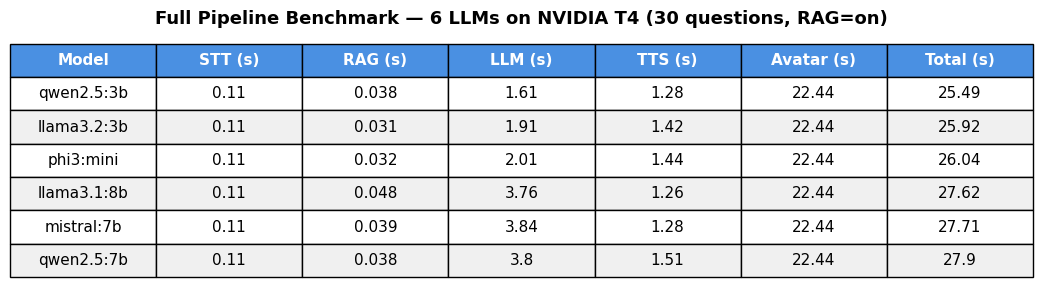


✓ Saved to /content/stages_table.png


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

summary_file = f'{PROJECT_DIR}/evaluation/results/stages_summary_20261011_104315.csv'
df = pd.read_csv(summary_file)

# Prepare display
df = df[['model', 'stt_s', 'rag_s', 'llm_s', 'tts_s', 'avatar_s', 'total_s']]
df = df.round({'stt_s': 3, 'rag_s': 3, 'llm_s': 2, 'tts_s': 2, 'avatar_s': 2, 'total_s': 2})
df = df.sort_values('total_s').reset_index(drop=True)

# Rename columns for publication
df.columns = ['Model', 'STT (s)', 'RAG (s)', 'LLM (s)', 'TTS (s)', 'Avatar (s)', 'Total (s)']

# Render table as image
fig, ax = plt.subplots(figsize=(12, 3))
ax.axis('off')
tbl = ax.table(cellText=df.values, colLabels=df.columns,
               loc='center', cellLoc='center',
               colColours=['#4a90e2']*len(df.columns))

# Styling
tbl.auto_set_font_size(False)
tbl.set_fontsize(11)
tbl.scale(1.1, 2.0)

# Make header white text
for i in range(len(df.columns)):
    tbl[(0, i)].set_text_props(weight='bold', color='white')

# Alternate row colors
for i in range(1, len(df)+1):
    for j in range(len(df.columns)):
        if i % 2 == 0:
            tbl[(i, j)].set_facecolor('#f0f0f0')

plt.title('Full Pipeline Benchmark — 6 LLMs on NVIDIA T4 (30 questions, RAG=on)',
          fontsize=13, fontweight='bold', pad=15)
plt.savefig('/content/stages_table.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print('\n✓ Saved to /content/stages_table.png')

## Cell 21 — Add gemini LLM model - Verify Gemini API Key


In [ ]:
from google.colab import userdata
try:
    key = userdata.get('GEMINI_API_KEY')
    print(f'✓ Key loaded, length={len(key)}, starts with: {key[:10]}...')
except Exception as e:
    print(f'FAIL: {e}')


✓ Key loaded, length=40, starts with: ghp_jPuai1...


In [ ]:
from google.colab import userdata
key = userdata.get('GEMINI_API_KEY')
print(f'Length: {len(key)}')
print(f'First 10 chars: {key[:10]}')
print(f'Last 5 chars: {key[-5:]}')
print(f'Has whitespace? {any(c.isspace() for c in key)}')
print(f'Starts with "AIza"? {key.startswith("AIza")}')


Length: 40
First 10 chars: ghp_jPuai1
Last 5 chars: 2WdqS
Has whitespace? False
Starts with "AIza"? False


In [ ]:
from google.colab import userdata
key = userdata.get('GEMINI_API_KEY')
print(f'Length: {len(key)}')
print(f'First 10: {key[:10]}')
print(f'Format: {"legacy (AIza)" if key.startswith("AIza") else "new (AQ.)" if key.startswith("AQ.") else "UNKNOWN"}')
print(f'Valid Gemini key? {key.startswith(("AIza", "AQ."))}')


Length: 53
First 10: AQ.Ab8RN6L
Format: new (AQ.)
Valid Gemini key? True


## Cell 22 (quick Gemini API test)

In [ ]:
from google.colab import userdata
import requests

key = userdata.get('GEMINI_API_KEY').strip()

# Try newer models
for model in ['gemini-3.8-flash', 'gemini-3.8-pro', 'gemini-3.5-flash']:
    url = f'https://generativelanguage.googleapis.com/v1beta/models/{model}:generateContent?key={key}'
    try:
        r = requests.post(url, json={
            'contents': [{'parts': [{'text': 'Say hello in one word.'}]}]
        }, timeout=30)
        if r.ok:
            print(f'✓ {model}: {r.json()["candidates"][0]["content"]["parts"][0]["text"]}')
        else:
            err = r.json().get('error', {}).get('message', r.text[:200])
            print(f'✗ {model}: {r.status_code} - {err[:150]}')
    except Exception as e:
        print(f'✗ {model}: {e}')


✗ gemini-3.8-flash: HTTPSConnectionPool(host='generativelanguage.googleapis.com', port=443): Read timed out. (read timeout=30)
✗ gemini-3.8-pro: 404 - models/gemini-3.8-pro is not found for API version v1beta, or is not supported for generateContent. Call ModelService.ListModels to see the list of av
✓ gemini-3.5-flash: Hello


## Cell 23

In [ ]:
!cd {PROJECT_DIR} && git pull && ls {PROJECT_DIR}/core/llm.py


remote: Enumerating objects: 13, done.
remote: Counting objects: 100% (13/13), done.
remote: Compressing objects: 100% (5/5), done.
remote: Total 8 (delta 5), reused 4 (delta 3), pack-reused 0 (from 0)
Unpacking objects: 100% (8/8), 61.59 KiB | 941.00 KiB/s, done.
From https://github.com/thomaskopalidis/thesis_ai_and_dl
   4333011..ed65fa6  master     -> origin/master
Updating 4333011..ed65fa6
Fast-forward
 colab/thesis_benchmark.ipynb | 1017 +++++++++++++++++++++++++++++++++++++++---
 core/llm.py                  |  148 +++++-
 2 files changed, 1085 insertions(+), 80 deletions(-)
/content/thesis_ai_and_dl/core/llm.py


## Cell 24 Quick Gemini test μέσω του project wrapper

In [ ]:
import os, sys
from google.colab import userdata

# Set env var so core/llm.py picks it up
os.environ['GEMINI_API_KEY'] = userdata.get('GEMINI_API_KEY')

# Clear module cache for fresh config
for mod in list(sys.modules.keys()):
    if mod == 'config' or mod.startswith('core.'):
        del sys.modules[mod]

sys.path.insert(0, PROJECT_DIR)
from core.llm import stream_llm_response
import time

t0 = time.time()
parts = []
for tok in stream_llm_response("What is Newton's second law?", model='cloud:google:gemini-3.5-flash'):
    parts.append(tok)
answer = ''.join(parts).strip()
print(f'[TIMING] {time.time()-t0:.2f}s')
print(f'A: {answer}')


[TIMING] 1.45s
A: Cloud error (google): unexpected response {'candidates': [{'content': {}, 'finishReason': 'MAX_TOKENS', 'index': 0}], 'usageMetadata': {'promptTokenCount': 72, 'totalTokenCount': 148, 'promptTokensDetails': [{'modality': 'TEXT', 'tokenCount':


## Cell 25 - Benchmark Gemini

In [ ]:
import os
os.chdir(PROJECT_DIR)
os.environ['OLLAMA_READ_TIMEOUT'] = '300'
from google.colab import userdata
os.environ['GEMINI_API_KEY'] = userdata.get('GEMINI_API_KEY')

!python evaluation/benchmark_full_pipeline.py \
    --models cloud:google:gemini-3.5-flash \
    --runs 1 --warmups 1 \
    --skip-stt --skip-avatar


[2026-10-11T11:51:54] === Full pipeline benchmark ===
[2026-10-11T11:51:54] Models:    ['cloud:google:gemini-3.5-flash']
[2026-10-11T11:51:54] RAG:       on
[2026-10-11T11:51:54] Runs/Q:    1 (+1 warm-up per config)
[2026-10-11T11:51:54] Max tok:   50
[2026-10-11T11:51:54] CSV:       /content/thesis_ai_and_dl/evaluation/results/pipeline_20261011_115154.csv
[2026-10-11T11:51:54] 
[2026-10-11T11:51:54] ── Per-model LLM/TTS/RAG on 30 questions × 1 rag × 1 runs ──
[2026-10-11T11:51:54] ── cloud:google:gemini-3.5-flash  rag=on ──
Loading weights: 100% 103/103 [00:00<00:00, 4658.08it/s]
[RAG] Loaded existing collection: 3950 chunks
[2026-10-11T11:52:11]   warmup 1/1 ok
[2026-10-11T11:52:13]   Q01 r1: rag=0.027s llm=1.68s tts=0.64s hit@3=1
[2026-10-11T11:52:15]   Q02 r1: rag=0.028s llm=1.33s tts=0.72s hit@3=1
[2026-10-11T11:52:18]   Q03 r1: rag=0.033s llm=1.81s tts=0.73s hit@3=1
[2026-10-11T11:52:21]   Q04 r1: rag=0.030s llm=1.23s tts=1.27s hit@3=1
[2026-10-11T11:52:25]   Q05 r1: rag=0.027s l

In [ ]:
!cd {PROJECT_DIR} && git pull


Already up to date.


##------ FOR DEMO -----

##CELL 8 — Upgrade Ollama

In [15]:
import subprocess, time
subprocess.run(['pkill', '-9', '-f', 'ollama'], check=False)
time.sleep(2)
!apt-get install -y -qq zstd >/dev/null
!curl -fsSL https://ollama.com/install.sh | sh 2>&1 | tail -3
!ollama --version


name, memory.total [MiB]
Tesla T4, 15360 MiB
>>> Cleaning up old version at /usr/local/lib/ollama
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...
>>> NVIDIA GPU installed.
>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.
ollama version is 0.40.5

NAME          ID              SIZE      PROCESSOR    CONTEXT    RUNNER      UNTIL              
qwen2.5:3b    357c53fb659c    2.2 GB    100% GPU     4096       llamacpp    4 minutes from now    


In [16]:
import subprocess

# Verify installation path
print('=== which ollama ===')
!which ollama
!ls -la /usr/local/bin/ollama 2>&1 | head -2

# Force PATH to use NEW ollama first
import os
os.environ['PATH'] = '/usr/local/bin:' + os.environ.get('PATH', '')

print('\n=== Version check ===')
!/usr/local/bin/ollama --version


=== which ollama ===
/usr/local/bin/ollama
-rwxr-xr-x 1 root root 29946960 Oct 15 18:39 /usr/local/bin/ollama

=== Version check ===
ollama version is 0.40.5


In [10]:
import subprocess, time, requests, os

# ─── 1. Kill ALL ollama processes ───
subprocess.run(['pkill', '-9', '-f', 'ollama'], check=False)
time.sleep(3)

# ─── 2. Remove old binary / force PATH to new ───
import shutil
old_binary = '/content/ollama_bin/bin/ollama'
if os.path.exists(old_binary):
    os.remove(old_binary)
    print(f'✓ Removed old binary at {old_binary}')

# Make sure new ollama is first in PATH
os.environ['PATH'] = '/usr/local/bin:' + os.environ.get('PATH', '')

# ─── 3. Verify ───
print('\n=== Which ollama ===')
!which ollama
print('\n=== Version ===')
!ollama --version

# ─── 4. Start NEW ollama server ───
print('\n=== Starting server ===')
env = os.environ.copy()
env['OLLAMA_MODELS'] = f'{THESIS_ROOT}/ollama_models'
env['PATH'] = '/usr/local/bin:' + env.get('PATH', '')

log_path = f'{THESIS_ROOT}/logs/ollama_serve.log'
with open(log_path, 'ab') as f:
    subprocess.Popen(['/usr/local/bin/ollama', 'serve'], stdout=f, stderr=subprocess.STDOUT, env=env)

for i in range(30):
    try:
        r = requests.get('http://localhost:11434/api/tags', timeout=1)
        if r.ok:
            print(f'✓ Ready after {i+1}s')
            print(f'Models: {[m["name"] for m in r.json().get("models", [])]}')
            break
    except Exception: pass
    time.sleep(1)
else:
    print('[FAIL] check logs')
    !tail -20 {log_path}


✓ Removed old binary at /content/ollama_bin/bin/ollama

=== Which ollama ===
/usr/local/bin/ollama

=== Version ===

=== Starting server ===
✓ Ready after 12s
Models: ['llama3.2:3b', 'phi3:mini', 'mistral:7b', 'llama3.1:8b', 'qwen2.5:7b', 'qwen2.5:3b']


##CELL 9 — Restart Ollama server

In [17]:
import subprocess, time, requests, os
subprocess.run(['pkill', '-9', '-f', 'ollama'], check=False)
time.sleep(3)
env = os.environ.copy()
env['OLLAMA_MODELS'] = f'{THESIS_ROOT}/ollama_models'
log_path = f'{THESIS_ROOT}/logs/ollama_serve.log'
with open(log_path, 'ab') as f:
    subprocess.Popen(['ollama', 'serve'], stdout=f, stderr=subprocess.STDOUT, env=env)
for i in range(30):
    try:
        r = requests.get('http://localhost:11434/api/tags', timeout=1)
        if r.ok:
            print(f'✓ Ready | Models: {[m["name"] for m in r.json().get("models", [])]}')
            break
    except Exception: pass
    time.sleep(1)


✓ Ready | Models: ['qwen2.5:3b', 'llama3.2:3b', 'phi3:mini', 'mistral:7b', 'llama3.1:8b', 'qwen2.5:7b']


## CELL 10 — ChromaDB symlink

In [18]:
import os, shutil
DRIVE_CHROMA = f'{THESIS_ROOT}/chroma_db'
PROJECT_CHROMA = f'{PROJECT_DIR}/chroma_db'

if os.path.islink(PROJECT_CHROMA): os.unlink(PROJECT_CHROMA)
if os.path.exists(PROJECT_CHROMA) and not os.path.islink(PROJECT_CHROMA):
    shutil.rmtree(PROJECT_CHROMA)
if not os.path.islink(PROJECT_CHROMA):
    os.symlink(DRIVE_CHROMA, PROJECT_CHROMA)
print(f'✓ Symlink OK')
!ls -lah {DRIVE_CHROMA} | head -5


✓ Symlink OK
total 36M
drwx------ 3 root root 4.0K Oct 10 23:05 .
drwx------ 7 root root 4.0K Oct 10 22:11 ..
drwx------ 2 root root 4.0K Oct 10 23:05 129b2ca1-0750-4ff3-8441-86e23fb87752
-rw------- 1 root root  36M Oct 16 05:48 chroma.sqlite3


##CELL 11 — Wav2Lip setup (για avatar)

In [13]:
import os
WAV2LIP_DIR = f'{PROJECT_DIR}/Wav2Lip'

if not os.path.exists(WAV2LIP_DIR):
    !cd {PROJECT_DIR} && git clone https://github.com/Rudrabha/Wav2Lip.git

# Patches
!sed -i 's|librosa.output.write_wav(path, wav, sr=sr)|import soundfile as _sf; _sf.write(path, wav, sr)|g' {WAV2LIP_DIR}/audio.py
!sed -i 's|librosa.filters.mel(hp.sample_rate, hp.n_fft, n_mels=hp.num_mels,|librosa.filters.mel(sr=hp.sample_rate, n_fft=hp.n_fft, n_mels=hp.num_mels,|g' {WAV2LIP_DIR}/audio.py

# Checkpoints
CKPT = f'{WAV2LIP_DIR}/checkpoints/wav2lip_gan.pth'
if not os.path.exists(CKPT) or os.path.getsize(CKPT) < 400_000_000:
    os.makedirs(os.path.dirname(CKPT), exist_ok=True)
    !wget -q -O {CKPT} 'https://huggingface.co/numz/wav2lip_studio/resolve/main/Wav2lip/wav2lip_gan.pth'

FACE_DET = f'{WAV2LIP_DIR}/face_detection/detection/sfd/s3fd.pth'
if not os.path.exists(FACE_DET):
    os.makedirs(os.path.dirname(FACE_DET), exist_ok=True)
    !wget -q -O {FACE_DET} 'https://www.adrianbulat.com/downloads/python-fan/s3fd-619a316812.pth'

!pip install -q batch-face face-alignment
print(f'\n✓ Wav2Lip: {os.path.getsize(CKPT)/1e6:.0f} MB')
print(f'✓ FaceDet: {os.path.getsize(FACE_DET)/1e6:.0f} MB')


Cloning into 'Wav2Lip'...
remote: Enumerating objects: 409, done.
remote: Counting objects: 100% (4/4), done.
remote: Compressing objects: 100% (2/2), done.
remote: Total 409 (delta 2), reused 2 (delta 2), pack-reused 405 (from 2)
Receiving objects: 100% (409/409), 549.05 KiB | 16.15 MiB/s, done.
Resolving deltas: 100% (227/227), done.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 30.6/30.6 MB 14.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.1/45.1 kB 4.5 MB/s eta 0:00:00

✓ Wav2Lip: 436 MB
✓ FaceDet: 90 MB


##CELL 12 — LIVE DEMO

In [20]:
import subprocess, os, time, requests
from google.colab import userdata
from google.colab.output import eval_js

# ─── Kill previous server ───
subprocess.run(['pkill', '-9', '-f', 'app.py'], check=False)
subprocess.run(['pkill', '-9', '-f', 'uvicorn'], check=False)
time.sleep(2)

# ─── Load cloud API keys from secrets ───
for name in ['GEMINI_API_KEY', 'OPENROUTER_API_KEY', 'GROQ_API_KEY',
             'OPENAI_API_KEY', 'ANTHROPIC_API_KEY']:
    try:
        os.environ[name] = userdata.get(name)
        print(f'✓ {name}')
    except Exception:
        print(f'  (skip {name})')

# ─── Launch app.py ───
os.chdir(PROJECT_DIR)
print('\n🚀 Launching app.py...')
log_path = f'{THESIS_ROOT}/logs/app_server.log'
with open(log_path, 'wb') as log:
    proc = subprocess.Popen(['python', 'app.py'], stdout=log, stderr=subprocess.STDOUT)

# ─── Wait for server ready ───
ready = False
for i in range(60):
    try:
        r = requests.get('http://localhost:8000/api/models', timeout=1)
        if r.ok:
            print(f'\n✓ Server ready after {i+1}s')
            print(f'  Models available: {r.json()["models"]}')
            ready = True
            break
    except Exception:
        pass
    time.sleep(1)

if not ready:
    print('\n[FAIL] Server did not start. Logs:')
    !tail -30 {log_path}
else:
    # ─── Get public URL ───
    url = eval_js('google.colab.kernel.proxyPort(8000)')
    full_url = f'{url}app/'

    print('\n' + '═' * 70)
    print('🌐 LIVE DEMO URL (κάνε click για να ανοίξει σε νέο tab):')
    print('   ' + full_url)
    print('═' * 70)

    print('\n📝 Οδηγίες:')
    print('  1. Κάνε click στο URL παραπάνω')
    print('  2. Model dropdown:')
    print('     • "cloud:groq:qwen/qwen3.8-27b"  → fast (0.15s LLM)')
    print('     • "qwen2.5:3b"                    → local, για avatar')
    print('  3. Avatar toggle: OFF για γρήγορο | ON για video')
    print('  4. Chat: γράψε "What is Newton\'s second law?" ή οτιδήποτε')
    print('\n📊 Logs live:  !tail -f ' + log_path)
    print('🛑 Stop:        τρέξε το επόμενο cell')

    # Clickable HTML link
    from IPython.display import HTML, display
    display(HTML(f'<h2>🎬 <a href="{full_url}" target="_blank" style="color:#4a90e2;">ΑΝΟΙΞΕ ΤΟ LIVE DEMO ΕΔΩ ➡</a></h2>'))


✓ GEMINI_API_KEY
✓ OPENROUTER_API_KEY
✓ GROQ_API_KEY
  (skip OPENAI_API_KEY)
  (skip ANTHROPIC_API_KEY)

🚀 Launching app.py...

✓ Server ready after 7s
  Models available: ['qwen2.5:7b']

══════════════════════════════════════════════════════════════════════
🌐 LIVE DEMO URL (κάνε click για να ανοίξει σε νέο tab):
   https://8000-gpu-t4-s-kkb-ass1c1-3bshuoec586m7-c.asia-southeast1-1.prod.colab.devapp/
══════════════════════════════════════════════════════════════════════

📝 Οδηγίες:
  1. Κάνε click στο URL παραπάνω
  2. Model dropdown:
     • "cloud:groq:qwen/qwen3.8-27b"  → fast (0.15s LLM)
     • "qwen2.5:3b"                    → local, για avatar
  3. Avatar toggle: OFF για γρήγορο | ON για video
  4. Chat: γράψε "What is Newton's second law?" ή οτιδήποτε

📊 Logs live:  !tail -f /content/drive/MyDrive/thesis_ai_and_dl/logs/app_server.log
🛑 Stop:        τρέξε το επόμενο cell


In [21]:
!pip install -q pyngrok
from pyngrok import ngrok, conf
from google.colab import userdata

conf.get_default().auth_token = userdata.get('NGROK_TOKEN')
ngrok.kill()

public_url = ngrok.connect(8000, "http")
demo_url = f"{public_url.public_url}/app/"
print(f"\n{'='*60}")
print(f"🎬 LIVE DEMO URL:")
print(f"{demo_url}")
print(f"{'='*60}\n")



🎬 LIVE DEMO URL:
https://katerine-pharmacognostic-kamila.ngrok-free.dev/app/



In [22]:
%cd /content/thesis_ai_and_dl
!git pull



/content/thesis_ai_and_dl
Already up to date.


In [23]:
!pkill -f "python3 app.py"
import time; time.sleep(2)

import subprocess
subprocess.Popen(['python3', 'app.py'],
                 stdout=open('/tmp/app.log', 'w'),
                 stderr=subprocess.STDOUT,
                 cwd='/content/thesis_ai_and_dl')
time.sleep(5)
print("✓ Server restarted")


✓ Server restarted


## Check if the llm and ollama works

In [24]:
!tail -50 /tmp/app.log


INFO:     Started server process [7423]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://0.0.0.0:8000 (Press CTRL+C to quit)
[TTS] chatterbox loaded
[TTS] Available: ['edge', 'chatterbox'] | Default: edge
[MuseTalk Import Error]: No module named 'musetalk'
[ENGINE] Available: ['wav2lip', 'musetalk', 'sadtalker'] | Default: wav2lip
[TTS] chatterbox loaded
[TTS] Available: ['edge', 'chatterbox'] | Default: edge
[ENGINE] Available: ['wav2lip', 'musetalk', 'sadtalker'] | Default: wav2lip
INFO:     2a02:214c:8494:db00:3833:cb1f:233d:22ff:0 - "GET /app/ HTTP/1.1" 200 OK
INFO:     2a02:214c:8494:db00:3833:cb1f:233d:22ff:0 - "GET /app/assets/teacher_avatar.jpg HTTP/1.1" 200 OK
INFO:     2a02:214c:8494:db00:3833:cb1f:233d:22ff:0 - "GET /app/main.js HTTP/1.1" 200 OK
INFO:     2a02:214c:8494:db00:3833:cb1f:233d:22ff:0 - "GET /api/models HTTP/1.1" 200 OK
INFO:     2a02:214c:8494:db00:3833:cb1f:233d:22ff:0 - "WebSocket /ws/chat" 

In [25]:
!curl -s http://localhost:11434/api/tags | python3 -c "import json,sys; d=json.load(sys.stdin); print('Models loaded:', [m['name'] for m in d.get('models', [])])"
!ps aux | grep -E "ollama|python3 app" | grep -v grep


Traceback (most recent call last):
  File "<string>", line 1, in <module>
    import json,sys; d=json.load(sys.stdin); print('Models loaded:', [m['name'] for m in d.get('models', [])])
                       ~~~~~~~~~^^^^^^^^^^^
  File "/usr/lib/python3.13/json/__init__.py", line 298, in load
    return loads(fp.read(),
        cls=cls, object_hook=object_hook,
        parse_float=parse_float, parse_int=parse_int,
        parse_constant=parse_constant, object_pairs_hook=object_pairs_hook, **kw)
  File "/usr/lib/python3.13/json/__init__.py", line 352, in loads
    return _default_decoder.decode(s)
           ~~~~~~~~~~~~~~~~~~~~~~~^^^
  File "/usr/lib/python3.13/json/decoder.py", line 345, in decode
    obj, end = self.raw_decode(s, idx=_w(s, 0).end())
               ~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/lib/python3.13/json/decoder.py", line 363, in raw_decode
    raise JSONDecodeError("Expecting value", s, err.value) from None
json.decoder.JSONDecodeError: Expecting value

In [26]:
%cd /content/thesis_ai_and_dl
!git pull
!pkill -f "python3 app.py"
import time, subprocess
time.sleep(3)
subprocess.Popen(['python3', 'app.py'],
                 stdout=open('/tmp/app.log','w'),
                 stderr=subprocess.STDOUT,
                 cwd='/content/thesis_ai_and_dl')
time.sleep(6)
print("✓ Server restarted")
!tail -10 /tmp/app.log


/content/thesis_ai_and_dl
Already up to date.
✓ Server restarted
INFO:     Started server process [9049]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://0.0.0.0:8000 (Press CTRL+C to quit)


In [27]:
!ollama list
for m in ["qwen2.5:3b", "llama3.1:8b", "llama3.2:3b", "mistral:7b", "phi3:mini"]:
    !ollama pull {m}
!ollama list

Error: could not connect to ollama server, run 'ollama serve' to start it
Error: could not connect to ollama server, run 'ollama serve' to start it
Error: could not connect to ollama server, run 'ollama serve' to start it
Error: could not connect to ollama server, run 'ollama serve' to start it
Error: could not connect to ollama server, run 'ollama serve' to start it
Error: could not connect to ollama server, run 'ollama serve' to start it
Error: could not connect to ollama server, run 'ollama serve' to start it


In [28]:
# === Start Ollama server and wait until it responds ===
import subprocess, time, urllib.request

!pkill -f "ollama serve"
subprocess.Popen("nohup ollama serve > /content/ollama.log 2>&1 &", shell=True)

for i in range(30):                       # wait up to 30 s
    try:
        urllib.request.urlopen("http://127.0.0.1:11434", timeout=2)
        print(f"✓ Ollama is running (after {i+1} s)")
        break
    except Exception:
        time.sleep(1)
else:
    print("✗ Ollama did not start. Last log lines:")
    !tail -20 /content/ollama.log

!ollama -v

✓ Ollama is running (after 3 s)
ollama version is 0.40.5


##CELL 13 — Stop server

In [29]:
import subprocess
subprocess.run(['pkill', '-9', '-f', 'app.py'], check=False)
subprocess.run(['pkill', '-9', '-f', 'uvicorn'], check=False)
print('✓ Server stopped')


✓ Server stopped


In [ ]:
# === Step 0 — Test 3b: Wav2Lip on a VIDEO base via the new AvatarEngine ===
import os, sys
os.chdir(PROJECT_DIR); sys.path.insert(0, PROJECT_DIR)
for m in list(sys.modules):                      # fresh imports
    if m == 'config' or m.startswith('core'):
        del sys.modules[m]
from core import avatar_engine
print('Available engines:', avatar_engine.available_engines())

AUDIO = 'evaluation/audio/synthetic/Q05.wav'
assert os.path.isfile(AUDIO), 'Run the cell that generates the synthetic wavs first (Cell 18.5)'

# 3-second test video, 25 fps, aspect ratio preserved
!ffmpeg -y -loglevel error -loop 1 -i frontend/assets/teacher_avatar.jpg -t 3 -r 25 -vf "scale=-2:512" -pix_fmt yuv420p -c:v libx264 _test_video.mp4

r = avatar_engine.get('wav2lip').generate(AUDIO, base_path='_test_video.mp4')
print(f'base_kind={r.base_kind} time={r.time_s:.2f}s dur={r.video_duration_s:.2f}s '
      f'fps={r.fps:.1f} vram={r.peak_vram_mb:.0f}MB encode={r.encode_time_s:.2f}s')

from IPython.display import Video
Video(r.video_path, embed=True, width=320)

## Stop the Colab

In [30]:
# === STOP NOW: save Drive and delete the runtime ===
from google.colab import runtime, drive
try: drive.flush_and_unmount()
except Exception as e: print("Drive flush warning:", e)
runtime.unassign()